# Docling test: parsing "Attention Is All You Need"

This notebook runs docling on the PDF and inspects the output (text, structure, tables, export formats).

In [2]:
%pip install -q docling

In [3]:
import urllib.request

PDF_FILENAME = "Attention Is All You Need.pdf"
urllib.request.urlretrieve("https://arxiv.org/pdf/1706.03762.pdf", PDF_FILENAME)
PDF_FILENAME

'Attention Is All You Need.pdf'

In [4]:
from pathlib import Path
from docling.document_converter import DocumentConverter

PDF_PATH = Path(PDF_FILENAME)
assert PDF_PATH.exists(), f"File not found: {PDF_PATH}"
PDF_PATH

PosixPath('Attention Is All You Need.pdf')

In [5]:
from docling.document_converter import PdfFormatOption
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.datamodel.base_models import InputFormat

pipeline_options = PdfPipelineOptions()
pipeline_options.do_ocr = False  # text-based PDF; avoids downloading the OCR model (was failing on SSL cert verification)
pipeline_options.generate_picture_images = True  # keep rendered images so we can display them below

converter = DocumentConverter(
    format_options={
        InputFormat.PDF: PdfFormatOption(pipeline_options=pipeline_options)
    }
)
result = converter.convert(str(PDF_PATH))
doc = result.document
result.status

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

<ConversionStatus.SUCCESS: 'success'>

## Export to markdown

In [6]:
markdown_text = doc.export_to_markdown()
print(markdown_text[:3000])

Provided proper attribution is provided, Google hereby grants permission to reproduce the tables and figures in this paper solely for use in journalistic or scholarly works.

## Attention Is All You Need

Ashish Vaswani ∗ Google Brain avaswani@google.com Noam Shazeer ∗ Google Brain noam@google.com

Llion Jones ∗ Google Research llion@google.com Niki Parmar ∗ Google Research nikip@google.com Aidan N. Gomez ∗ † University of Toronto aidan@cs.toronto.edu Jakob Uszkoreit ∗ Google Research usz@google.com Łukasz Kaiser ∗ Google Brain lukaszkaiser@google.com Illia Polosukhin ∗ ‡

illia.polosukhin@gmail.com

## Abstract

The dominant sequence transduction models are based on complex recurrent or convolutional neural networks that include an encoder and a decoder. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convol

In [7]:
out_dir = Path("attention_is_all_you_need_parsed_docling")
out_dir.mkdir(exist_ok=True)

md_path = out_dir / "attention_is_all_you_need.md"
md_path.write_text(markdown_text, encoding="utf-8")
md_path

PosixPath('attention_is_all_you_need_parsed_docling/attention_is_all_you_need.md')

## Document structure overview

In [8]:
print("Number of pages:", len(doc.pages))
print("Number of tables:", len(doc.tables))
print("Number of pictures:", len(doc.pictures))
print("Number of texts:", len(doc.texts))

Number of pages: 15
Number of tables: 4
Number of pictures: 6
Number of texts: 458


In [9]:
for i, item in enumerate(doc.texts[:20]):
    print(f"[{i}] ({item.label}) {item.text[:100]!r}")

[0] (page_header) 'arXiv:1706.03762v7  [cs.CL]  2 Aug 2023'
[1] (text) 'Provided proper attribution is provided, Google hereby grants permission to reproduce the tables and'
[2] (section_header) 'Attention Is All You Need'
[3] (text) 'Ashish Vaswani ∗ Google Brain avaswani@google.com Noam Shazeer ∗ Google Brain noam@google.com'
[4] (text) 'Llion Jones ∗ Google Research llion@google.com Niki Parmar ∗ Google Research nikip@google.com Aidan '
[5] (text) 'illia.polosukhin@gmail.com'
[6] (section_header) 'Abstract'
[7] (text) 'The dominant sequence transduction models are based on complex recurrent or convolutional neural net'
[8] (footnote) '∗ Equal contribution. Listing order is random. Jakob proposed replacing RNNs with self-attention and'
[9] (footnote) '† Work performed while at Google Brain.'
[10] (footnote) '‡ Work performed while at Google Research.'
[11] (page_footer) '31st Conference on Neural Information Processing Systems (NIPS 2017), Long Beach, CA, USA.'
[12] (section_header) 

## Tables

In [10]:
for i, table in enumerate(doc.tables):
    print(f"--- Table {i} (page {table.prov[0].page_no if table.prov else '?'}) ---")
    df = table.export_to_dataframe()
    display(df)

--- Table 0 (page 6) ---


,Layer Type,Complexity per Layer,Sequential Operations,Maximum Path Length
0,Self-Attention,O ( n 2 · d ),O (1),O (1)
1,Recurrent,O ( n · d 2 ),O ( n ),O ( n )
2,Convolutional,O ( k · n · d 2 ),O (1),O ( log k ( n ))
3,Self-Attention (restricted),O ( r · n · d ),O (1),O ( n/r )


--- Table 1 (page 8) ---


,Model.,BLEU.EN-DE,BLEU.EN-FR,Training Cost (FLOPs).EN-DE,Training Cost (FLOPs).EN-FR
0,ByteNet [18],23.75,,,
1,Deep-Att + PosUnk [39],,39.2,,1 . 0 · 10 20
2,GNMT + RL [38],24.6,39.92,2 . 3 · 10 19,1 . 4 · 10 20
3,ConvS2S [9],25.16,40.46,9 . 6 · 10 18,1 . 5 · 10 20
4,MoE [32],26.03,40.56,2 . 0 · 10 19,1 . 2 · 10 20
5,Deep-Att + PosUnk Ensemble [39],,40.4,,8 . 0 · 10 20
6,GNMT + RL Ensemble [38],26.30,41.16,1 . 8 · 10 20,1 . 1 · 10 21
7,ConvS2S Ensemble [9],26.36,41.29,7 . 7 · 10 19,1 . 2 · 10 21
8,Transformer (base model),27.3,38.1,3 . 3 · 10 18,3 . 3 · 10 18
9,Transformer (big),28.4,41.8,2 . 3 · 10 19,2 . 3 · 10 19


--- Table 2 (page 9) ---


,,N,d model,d ff,h,d k,d v,P drop,ϵ ls,train steps,PPL (dev),BLEU (dev),params × 10 6
0,base,6,512,2048,8,64,64,0.1,0.1,100K,4.92,25.8,65
1,,,,,1,512,512,,,,5.29,24.9,
2,,,,,4,128,128,,,,5.00,25.5,
3,(A),,,,16,32,32,,,,4.91,25.8,
4,,,,,32,16,16,,,,5.01,25.4,
5,,,,,,16,,,,,5.16,25.1,58
6,(B),,,,,32,,,,,5.01,25.4,60
7,,2,,,,,,,,,6.11,23.7,36
8,,4,,,,,,,,,5.19,25.3,50
9,,8,,,,,,,,,4.88,25.5,80


--- Table 3 (page 10) ---


,Parser,Training,WSJ 23 F1
0,Vinyals &Kaiser el al. (2014) [37],"WSJ only, discriminative",88.3
1,Petrov et al. (2006) [29],"WSJ only, discriminative",90.4
2,Zhu et al. (2013) [40],"WSJ only, discriminative",90.4
3,Dyer et al. (2016) [8],"WSJ only, discriminative",91.7
4,Transformer (4 layers),"WSJ only, discriminative",91.3
5,Zhu et al. (2013) [40],semi-supervised,91.3
6,Huang &Harper (2009) [14],semi-supervised,91.3
7,McClosky et al. (2006) [26],semi-supervised,92.1
8,Vinyals &Kaiser el al. (2014) [37],semi-supervised,92.1
9,Transformer (4 layers),semi-supervised,92.7


## Pictures

--- Picture 0 (page 3) ---


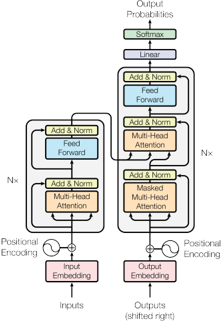

--- Picture 1 (page 4) ---


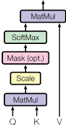

--- Picture 2 (page 4) ---


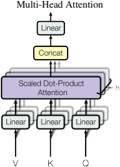

--- Picture 3 (page 13) ---


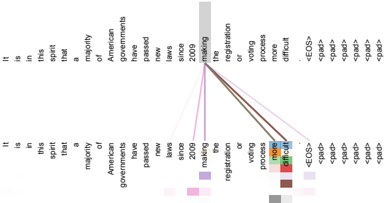

--- Picture 4 (page 14) ---


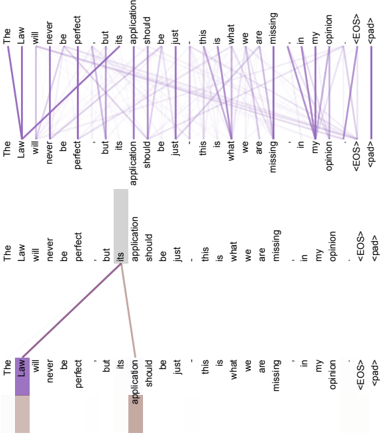

--- Picture 5 (page 15) ---


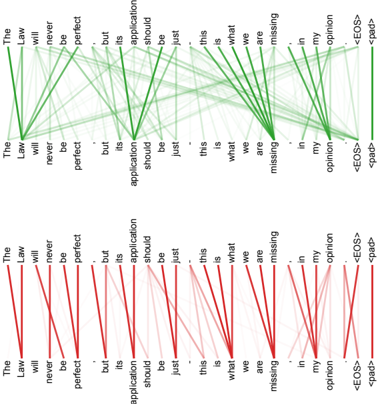

In [11]:
images_dir = out_dir / "images"
images_dir.mkdir(exist_ok=True)

for i, picture in enumerate(doc.pictures):
    page_no = picture.prov[0].page_no if picture.prov else "?"
    print(f"--- Picture {i} (page {page_no}) ---")
    image = picture.get_image(doc)
    if image is not None:
        image.save(images_dir / f"picture_{i}.png")
        display(image)
    else:
        print("(no rendered image available)")

## Export to JSON (full docling document model)

In [12]:
import json

doc_dict = doc.export_to_dict()
json_path = out_dir / "attention_is_all_you_need.json"
json_path.write_text(json.dumps(doc_dict, indent=2), encoding="utf-8")
json_path

PosixPath('attention_is_all_you_need_parsed_docling/attention_is_all_you_need.json')

## Package output for transfer

Drive and download widgets aren't available from this VS Code <-> Colab connection, so we
base64-encode the output folder and print it. The print output gets saved into this local
`.ipynb` file by VS Code even though the kernel runs on Colab, so it can be decoded back
into real files on the local machine afterward.

In [13]:
import base64
import shutil

zip_base = "attention_is_all_you_need_parsed_docling"
zip_path = shutil.make_archive(zip_base, "zip", out_dir)

with open(zip_path, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("ascii")

print(f"Zip size: {Path(zip_path).stat().st_size} bytes")
print("BASE64_ZIP_START")
print(encoded)
print("BASE64_ZIP_END")

Zip size: 763743 bytes
BASE64_ZIP_START
...
BASE64_ZIP_END
